In [1]:
from google.colab import files
uploaded = files.upload()

Saving district wise rainfall normal.csv to district wise rainfall normal.csv
Saving rainfall in india 1901-2015.csv to rainfall in india 1901-2015.csv


In [3]:
import pandas as pd
df = pd.read_csv("rainfall in india 1901-2015.csv")
print(df.shape)
df.head()

(4116, 19)


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
0,ANDAMAN & NICOBAR ISLANDS,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,ANDAMAN & NICOBAR ISLANDS,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,ANDAMAN & NICOBAR ISLANDS,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,ANDAMAN & NICOBAR ISLANDS,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,ANDAMAN & NICOBAR ISLANDS,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


In [4]:
kerala = df[df["SUBDIVISION"].str.strip().str.upper() == "KERALA"]
print(kerala.shape)
kerala.head()


(115, 19)


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
3887,KERALA,1901,28.7,44.7,51.6,160.0,174.7,824.6,743.0,357.5,197.7,266.9,350.8,48.4,3248.6,73.4,386.2,2122.8,666.1
3888,KERALA,1902,6.7,2.6,57.3,83.9,134.5,390.9,1205.0,315.8,491.6,358.4,158.3,121.5,3326.6,9.3,275.7,2403.4,638.2
3889,KERALA,1903,3.2,18.6,3.1,83.6,249.7,558.6,1022.5,420.2,341.8,354.1,157.0,59.0,3271.2,21.7,336.3,2343.0,570.1
3890,KERALA,1904,23.7,3.0,32.2,71.5,235.7,1098.2,725.5,351.8,222.7,328.1,33.9,3.3,3129.7,26.7,339.4,2398.2,365.3
3891,KERALA,1905,1.2,22.3,9.4,105.9,263.3,850.2,520.5,293.6,217.2,383.5,74.4,0.2,2741.6,23.4,378.5,1881.5,458.1


In [5]:
print(kerala.isna().sum())
print("Duplicate years:", kerala["YEAR"].duplicated().sum())


SUBDIVISION    0
YEAR           0
JAN            0
FEB            0
MAR            0
APR            0
MAY            0
JUN            0
JUL            0
AUG            0
SEP            0
OCT            0
NOV            0
DEC            0
ANNUAL         0
Jan-Feb        0
Mar-May        0
Jun-Sep        0
Oct-Dec        0
dtype: int64
Duplicate years: 0


In [6]:
months = ["JAN","FEB","MAR","APR","MAY","JUN","JUL","AUG","SEP","OCT","NOV","DEC"]

diff = (kerala[months].sum(axis=1) - kerala["ANNUAL"]).abs()

print("Biggest difference:", diff.max())
print("Rows off by more than 1 mm:", (diff > 1).sum())

Biggest difference: 0.3000000000001819
Rows off by more than 1 mm: 0


Validated 115 years of Kerala rainfall records: no missing values, no duplicate years, and monthly totals matched annual totals within 0.3 mm

In [12]:
import sqlite3

conn = sqlite3.connect("kerala_rain.db")
kerala.to_sql("rainfall", conn, if_exists="replace", index=False)

print(pd.read_sql("SELECT YEAR, ANNUAL FROM rainfall LIMIT 20", conn))

    YEAR  ANNUAL
0   1901  3248.6
1   1902  3326.6
2   1903  3271.2
3   1904  3129.7
4   1905  2741.6
5   1906  2708.0
6   1907  3671.1
7   1908  2648.3
8   1909  3050.2
9   1910  2848.6
10  1911  2726.7
11  1912  3451.3
12  1913  2610.8
13  1914  2899.1
14  1915  3024.5
15  1916  2945.3
16  1917  2704.8
17  1918  2501.9
18  1919  3003.3
19  1920  3303.1


In [14]:
query = """
SELECT YEAR, ANNUAL
FROM rainfall
ORDER BY ANNUAL ASC
LIMIT 5
"""
print(pd.read_sql(query, conn))

   YEAR  ANNUAL
0  1976  2068.8
1  1986  2093.2
2  1987  2137.6
3  2012  2151.1
4  1982  2223.3


In [15]:
query = """
SELECT (YEAR / 10) * 10 AS decade,
       ROUND(AVG(ANNUAL), 1) AS avg_rain_mm,
       COUNT(*) AS years
FROM rainfall
GROUP BY decade
ORDER BY decade
"""
print(pd.read_sql(query, conn))

    decade  avg_rain_mm  years
0     1900       3088.4      9
1     1910       2871.6     10
2     1920       3188.8     10
3     1930       3009.6     10
4     1940       3021.2     10
5     1950       2937.5     10
6     1960       3013.0     10
7     1970       2799.4     10
8     1980       2456.3     10
9     1990       3003.3     10
10    2000       2840.8     10
11    2010       2870.1      6


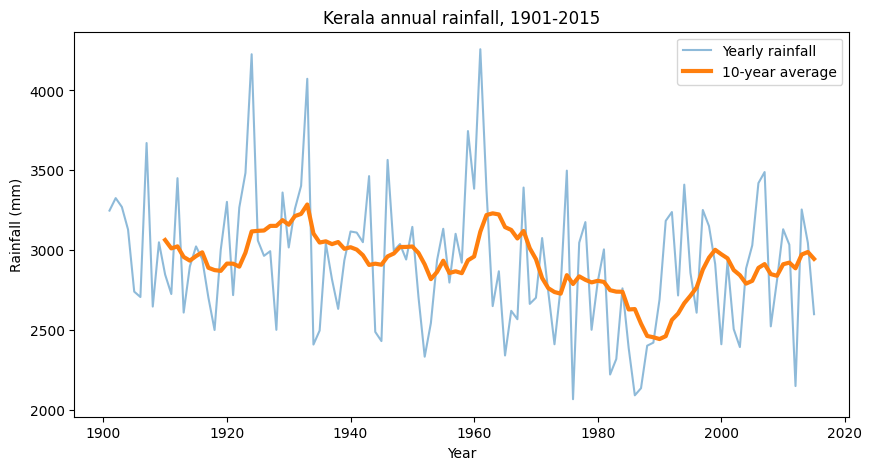

In [16]:
import matplotlib.pyplot as plt

kerala_sorted = kerala.sort_values("YEAR")
rolling = kerala_sorted["ANNUAL"].rolling(10).mean()

plt.figure(figsize=(10, 5))
plt.plot(kerala_sorted["YEAR"], kerala_sorted["ANNUAL"], label="Yearly rainfall", alpha=0.5)
plt.plot(kerala_sorted["YEAR"], rolling, label="10-year average", linewidth=3)
plt.title("Kerala annual rainfall, 1901-2015")
plt.xlabel("Year")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.show()

Rainfall peaked in the 1930s and early 1960s, fell to its lowest 10-year average around 1987-1990, and then recovered to roughly 3000 mm

In [17]:
plt.savefig("annual_rainfall.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

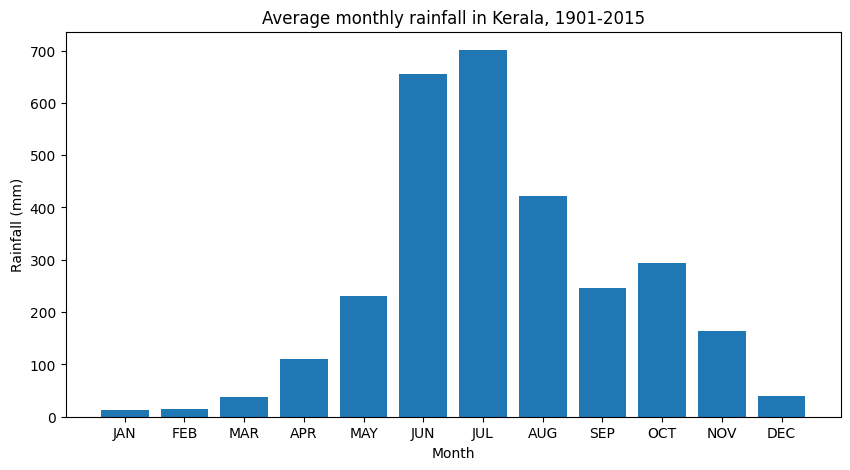

Share of yearly rain that falls June-September: 69.1 %


In [18]:
monthly_avg = kerala[months].mean()

plt.figure(figsize=(10, 5))
plt.bar(months, monthly_avg)
plt.title("Average monthly rainfall in Kerala, 1901-2015")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.savefig("monthly_rainfall.png", dpi=150, bbox_inches="tight")
plt.show()

monsoon_share = monthly_avg[["JUN", "JUL", "AUG", "SEP"]].sum() / monthly_avg.sum() * 100
print("Share of yearly rain that falls June-September:", round(monsoon_share, 1), "%")


69.1% of Kerala’s annual rainfall arrives in the June-September monsoon; July is the wettest month, with a smaller second peak in October

In [19]:
kerala_sorted = kerala.sort_values("YEAR")

data = kerala_sorted[["YEAR"]].copy()
data["jan_feb"] = kerala_sorted["JAN"] + kerala_sorted["FEB"]
data["mar_may"] = kerala_sorted[["MAR", "APR", "MAY"]].sum(axis=1)
data["monsoon"] = kerala_sorted[["JUN", "JUL", "AUG", "SEP"]].sum(axis=1)
data["prev_monsoon"] = data["monsoon"].shift(1)
data = data.dropna()

print(data.shape)
data.head()

(114, 5)


,YEAR,jan_feb,mar_may,monsoon,prev_monsoon
3888,1902,9.3,275.7,2403.3,2122.8
3889,1903,21.8,336.4,2343.1,2403.3
3890,1904,26.7,339.4,2398.2,2343.1
3891,1905,23.5,378.6,1881.5,2398.2
3892,1906,34.1,230.1,1943.1,1881.5


In [20]:
from sklearn.metrics import mean_absolute_error

train = data[data["YEAR"] < 1990]
test = data[data["YEAR"] >= 1990]

features = ["jan_feb", "mar_may", "prev_monsoon"]
X_train, y_train = train[features], train["monsoon"]
X_test, y_test = test[features], test["monsoon"]

print("Training years:", len(train), " Test years:", len(test))

baseline_guess = [y_train.mean()] * len(test)
print("Baseline MAE:", round(mean_absolute_error(y_test, baseline_guess), 1), "mm")

Training years: 88  Test years: 26
Baseline MAE: 319.3 mm


In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    print(name, "- MAE:", round(mae, 1), "mm, R2:", round(r2, 2))


Linear Regression - MAE: 321.3 mm, R2: -0.06
Random Forest - MAE: 342.9 mm, R2: -0.23


In [22]:
print(data[["jan_feb", "mar_may", "prev_monsoon", "monsoon"]].corr()["monsoon"].round(2))

jan_feb        -0.00
mar_may        -0.03
prev_monsoon    0.11
monsoon         1.00
Name: monsoon, dtype: float64
